In [1]:
from rouge import Rouge
from nltk.translate.bleu_score import sentence_bleu
from rouge_score import rouge_scorer
import datetime
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from dataloader import get_participants_data, get_participants_demographics
from stats import two_sample_test, pairwise_test
from scipy.spatial import ConvexHull
from nltk.tokenize import RegexpTokenizer
import pingouin as pg
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r'''\usepackage{libertine}\usepackage{fontawesome5}\usepackage{xcolor}'''
plt.rcParams['ps.usedistiller'] = 'xpdf'
sns.set_theme(style='ticks')
from statannotations.Annotator import Annotator
import scipy

In [2]:
interfaces = ['pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking']
df_begins = pd.DataFrame()
df_all = pd.DataFrame()
df_finishs = pd.DataFrame()
batches = [1, 2, 3, 4]

for batch in batches:
    for interface in interfaces:
        df_begin, df_iter, df_finish = get_participants_data('text', batch, interface)
        df_begin['interface'] = interface
        df_iter['interface'] = interface
        df_finish['interface'] = interface
        df_begins = pd.concat([df_begins, df_begin], ignore_index=True)
        df_all = pd.concat([df_all, df_iter], ignore_index=True)
        df_finishs = pd.concat([df_finishs, df_finish], ignore_index=True)

print(df_all.columns)
df_progress = df_all[['userID', 'taskID', 'interface', 'iteration', 'rating', 'skip', 'parameters', 'options', 'ground_truth']]
df_progress

Index(['userID', 'studyID', 'sessionID', 'taskID', 'feedbackID', 'groundTruth',
       'iteration', 'completeIteration', 'incompleteIteration', 'rating',
       'skip', 'parameters', 'timePresent', 'timeLastRating', 'timeSubmit',
       'comment', 'stop', 'options', 'ground_truth', 'interface', 'selection'],
      dtype='object')


,userID,taskID,interface,iteration,rating,skip,parameters,options,ground_truth
0,P330,3,pointwise,1,83,False,"[{'reduction_ratio': 0.1924789845943451, 'top_...",[Barcelona beat Atletico Madrid 3-0 to stay in...,Lionel Messi scores for the sixth game in a ro...
1,P330,3,pointwise,2,87,False,"[{'reduction_ratio': 0.7346476912498474, 'top_...",[Barcelona beat Atletico Madrid 3-0 to stay in...,Lionel Messi scores for the sixth game in a ro...
2,P330,3,pointwise,3,71,False,"[{'reduction_ratio': 0.9412690997123718, 'top_...",[Barcelona beat Atletico Madrid 3-0 to stay in...,Lionel Messi scores for the sixth game in a ro...
3,P330,3,pointwise,4,81,False,"[{'reduction_ratio': 0.5664541125297546, 'top_...",[Barcelona beat Atletico Madrid 3-0 to stay in...,Lionel Messi scores for the sixth game in a ro...
4,P330,3,pointwise,5,81,False,"[{'reduction_ratio': 0.34385254979133606, 'top...",[Barcelona beat Atletico Madrid 3-0 to stay in...,Lionel Messi scores for the sixth game in a ro...
...,...,...,...,...,...,...,...,...,...
3879,P249,2,listwise-ranking,3,"[{'id': 0, 'rating': 'Good', 'timestamp': 1662...",False,"[{'reduction_ratio': 0.8093615174293518, 'top_...",[Harry Potter star Daniel Radcliffe turns 18 o...,Harry Potter star Daniel Radcliffe gets £20M f...
3880,P249,2,listwise-ranking,4,"[{'id': 0, 'rating': 'Good', 'timestamp': 1662...",False,"[{'reduction_ratio': 0.12694059312343597, 'top...",[Harry Potter star Daniel Radcliffe turns 18 o...,Harry Potter star Daniel Radcliffe gets £20M f...
3881,P249,2,listwise-ranking,5,"[{'id': 0, 'rating': 'Good', 'timestamp': 1662...",False,"[{'reduction_ratio': 0.23951280117034912, 'top...",[Harry Potter star Daniel Radcliffe turns 18 o...,Harry Potter star Daniel Radcliffe gets £20M f...
3882,P249,2,listwise-ranking,6,"[{'id': 0, 'rating': 'Good', 'timestamp': 1662...",False,"[{'reduction_ratio': 0.8244489431381226, 'top_...",[Harry Potter star Daniel Radcliffe turns 18 o...,Harry Potter star Daniel Radcliffe gets £20M f...


In [3]:
def compute_objective_quality(df, redo=False):
    if not redo:
        return pd.read_csv('processed/quality.csv')

    rouge = Rouge()
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

    df_quality = df[['userID', 'taskID', 'iteration', 'stop', 'interface', 'options', 'ground_truth']]
    df_quality['length'] = 0
    df_quality['rouge1'] = 0
    df_quality['rouge2'] = 0
    df_quality['rougeL'] = 0
    df_quality['BLEU'] = 0

    for idx, row in df_quality.iterrows():
        count  = 0
        avglen = []
        rouge1s = []
        rouge2s = []
        rougeLs = []
        BLEUs = []
        for option in row.options:
            tokenizer = RegexpTokenizer(r'\w+')
            reference_token = tokenizer.tokenize(row['ground_truth'])
            summarized_token = tokenizer.tokenize(option)
            scores = scorer.score(row['ground_truth'], option)
            rouge1s.append(scores['rouge1'].fmeasure)
            rouge2s.append(scores['rouge2'].fmeasure)
            rougeLs.append(scores['rougeL'].fmeasure)
            BLEUs.append(sentence_bleu([reference_token], summarized_token))

            avglen.append(len(summarized_token))
            count += 1

        df_quality.loc[idx, 'rouge1'] = str(rouge1s)
        df_quality.loc[idx, 'rouge2'] = str(rouge2s)
        df_quality.loc[idx, 'rougeL'] = str(rougeLs)
        df_quality.loc[idx, 'BLEU'] = str(BLEUs)
        df_quality.loc[idx, 'length'] = str(avglen)

        df_quality.to_csv('processed/quality.csv')
    return df_quality

df_quality = compute_objective_quality(df_all, redo=False)
df_quality.length.apply(lambda x: eval(x))
df_quality.rouge1.apply(lambda x: eval(x))
df_quality.rouge2.apply(lambda x: eval(x))
df_quality.rougeL.apply(lambda x: eval(x))
df_quality.BLEU.apply(lambda x: eval(x))
df_quality.head()

,Unnamed: 0,userID,taskID,iteration,stop,interface,options,ground_truth,length,rouge1,rouge2,rougeL,BLEU
0,0,P330,3,1,False,pointwise,"[""Barcelona beat Atletico Madrid 3-0 to stay i...",Lionel Messi scores for the sixth game in a ro...,[65],[0.4444444444444445],[0.1509433962264151],[0.20370370370370372],[2.0093377568224993e-78]
1,1,P330,3,2,False,pointwise,"[""Barcelona beat Atletico Madrid 3-0 to stay i...",Lionel Messi scores for the sixth game in a ro...,[62],[0.4761904761904762],[0.1359223300970874],[0.20952380952380953],[2.0352952840394935e-78]
2,2,P330,3,3,False,pointwise,['Barcelona beat Atletico Madrid 3-0 to stay i...,Lionel Messi scores for the sixth game in a ro...,[47],[0.4222222222222222],[0.15909090909090912],[0.24444444444444444],[2.3484535096662163e-78]
3,3,P330,3,4,False,pointwise,"[""Barcelona beat Atletico Madrid 3-0 to stay i...",Lionel Messi scores for the sixth game in a ro...,[65],[0.4444444444444445],[0.1509433962264151],[0.20370370370370372],[2.0093377568224993e-78]
4,4,P330,3,5,False,pointwise,"[""Barcelona beat Atletico Madrid 3-0 to stay i...",Lionel Messi scores for the sixth game in a ro...,[65],[0.4444444444444445],[0.1509433962264151],[0.20370370370370372],[2.0093377568224993e-78]


In [4]:
normalize = False
if normalize:
    df_quality['length'] = (df_quality['length'] - df_quality['length'].min()) / (df_quality['length'].max() - df_quality['length'].min())
    # df_quality['rouge1'] = (df_quality['rouge1'] - df_quality['rouge1'].min()) / (df_quality['rouge1'].max() - df_quality['rouge1'].min())
    # df_quality['rouge2'] = (df_quality['rouge2'] - df_quality['rouge2'].min()) / (df_quality['rouge2'].max() - df_quality['rouge2'].min())
    # df_quality['rougeL'] = (df_quality['rougeL'] - df_quality['rougeL'].min()) / (df_quality['rougeL'].max() - df_quality['rougeL'].min())
    df_quality['BLEU'] = (df_quality['BLEU'] - df_quality['BLEU'].min()) / (df_quality['BLEU'].max() - df_quality['BLEU'].min())
df_quality.head()

,Unnamed: 0,userID,taskID,iteration,stop,interface,options,ground_truth,length,rouge1,rouge2,rougeL,BLEU
0,0,P330,3,1,False,pointwise,"[""Barcelona beat Atletico Madrid 3-0 to stay i...",Lionel Messi scores for the sixth game in a ro...,[65],[0.4444444444444445],[0.1509433962264151],[0.20370370370370372],[2.0093377568224993e-78]
1,1,P330,3,2,False,pointwise,"[""Barcelona beat Atletico Madrid 3-0 to stay i...",Lionel Messi scores for the sixth game in a ro...,[62],[0.4761904761904762],[0.1359223300970874],[0.20952380952380953],[2.0352952840394935e-78]
2,2,P330,3,3,False,pointwise,['Barcelona beat Atletico Madrid 3-0 to stay i...,Lionel Messi scores for the sixth game in a ro...,[47],[0.4222222222222222],[0.15909090909090912],[0.24444444444444444],[2.3484535096662163e-78]
3,3,P330,3,4,False,pointwise,"[""Barcelona beat Atletico Madrid 3-0 to stay i...",Lionel Messi scores for the sixth game in a ro...,[65],[0.4444444444444445],[0.1509433962264151],[0.20370370370370372],[2.0093377568224993e-78]
4,4,P330,3,5,False,pointwise,"[""Barcelona beat Atletico Madrid 3-0 to stay i...",Lionel Messi scores for the sixth game in a ro...,[65],[0.4444444444444445],[0.1509433962264151],[0.20370370370370372],[2.0093377568224993e-78]


In [5]:
for idx, row in df_quality.iterrows():
    df_quality.loc[idx, 'length'] = np.mean(eval(row['length']))
    df_quality.loc[idx, 'rouge1'] = np.mean(eval(row['rouge1']))
    df_quality.loc[idx, 'rouge2'] = np.mean(eval(row['rouge2']))
    df_quality.loc[idx, 'rougeL'] = np.mean(eval(row['rougeL']))
    df_quality.loc[idx, 'BLEU'] = np.mean(eval(row['BLEU']))

df_quality_temp = df_quality.groupby(['userID', 'taskID', 'interface']).agg({'length':  lambda x: list(x), 'rouge1': lambda x: list(x), 'rouge2': lambda x: list(x), 'rougeL': lambda x: list(x), 'BLEU': lambda x: list(x)}).reset_index()
df_quality_progress = pd.DataFrame()
for idx, row in df_quality_temp.iterrows():
    l = scipy.signal.resample(row['length'], 20)
    r1 = scipy.signal.resample(row['rouge1'], 20)
    r2 = scipy.signal.resample(row['rouge2'], 20)
    rL = scipy.signal.resample(row['rougeL'], 20)
    bleu = scipy.signal.resample(row['BLEU'], 20)

    for i, v in enumerate(l):
        df_quality_progress = df_quality_progress.append({
            'userID': row['userID'], 'taskID': row['taskID'], 'interface': row.interface, 'iteration': i, 
            'length': l[i], 'rouge1': r1[i], 'rouge2': r2[i], 'rougeL': rL[i], 'BLEU': bleu[i]
        }, ignore_index=True)

df_quality_progress

,userID,taskID,interface,iteration,length,rouge1,rouge2,rougeL,BLEU
0,P129,1,listwise-notie,0,42.000000,0.334696,0.094457,0.191011,1.470347e-78
1,P129,1,listwise-notie,1,40.568310,0.324749,0.094828,0.191667,1.462727e-78
2,P129,1,listwise-notie,2,38.644530,0.328466,0.085392,0.191568,9.831110e-79
3,P129,1,listwise-notie,3,37.740441,0.345662,0.074721,0.196769,3.099256e-79
4,P129,1,listwise-notie,4,38.965633,0.365797,0.072044,0.209675,-1.662203e-79
...,...,...,...,...,...,...,...,...,...
10775,P078,3,listwise-notie,15,60.098291,0.455831,0.169832,0.220185,-1.771874e-03
10776,P078,3,listwise-notie,16,60.820787,0.456152,0.163311,0.214768,4.830798e-04
10777,P078,3,listwise-notie,17,60.955106,0.460019,0.154646,0.212046,-1.055211e-03
10778,P078,3,listwise-notie,18,60.424493,0.466296,0.146370,0.213275,-5.964252e-03


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

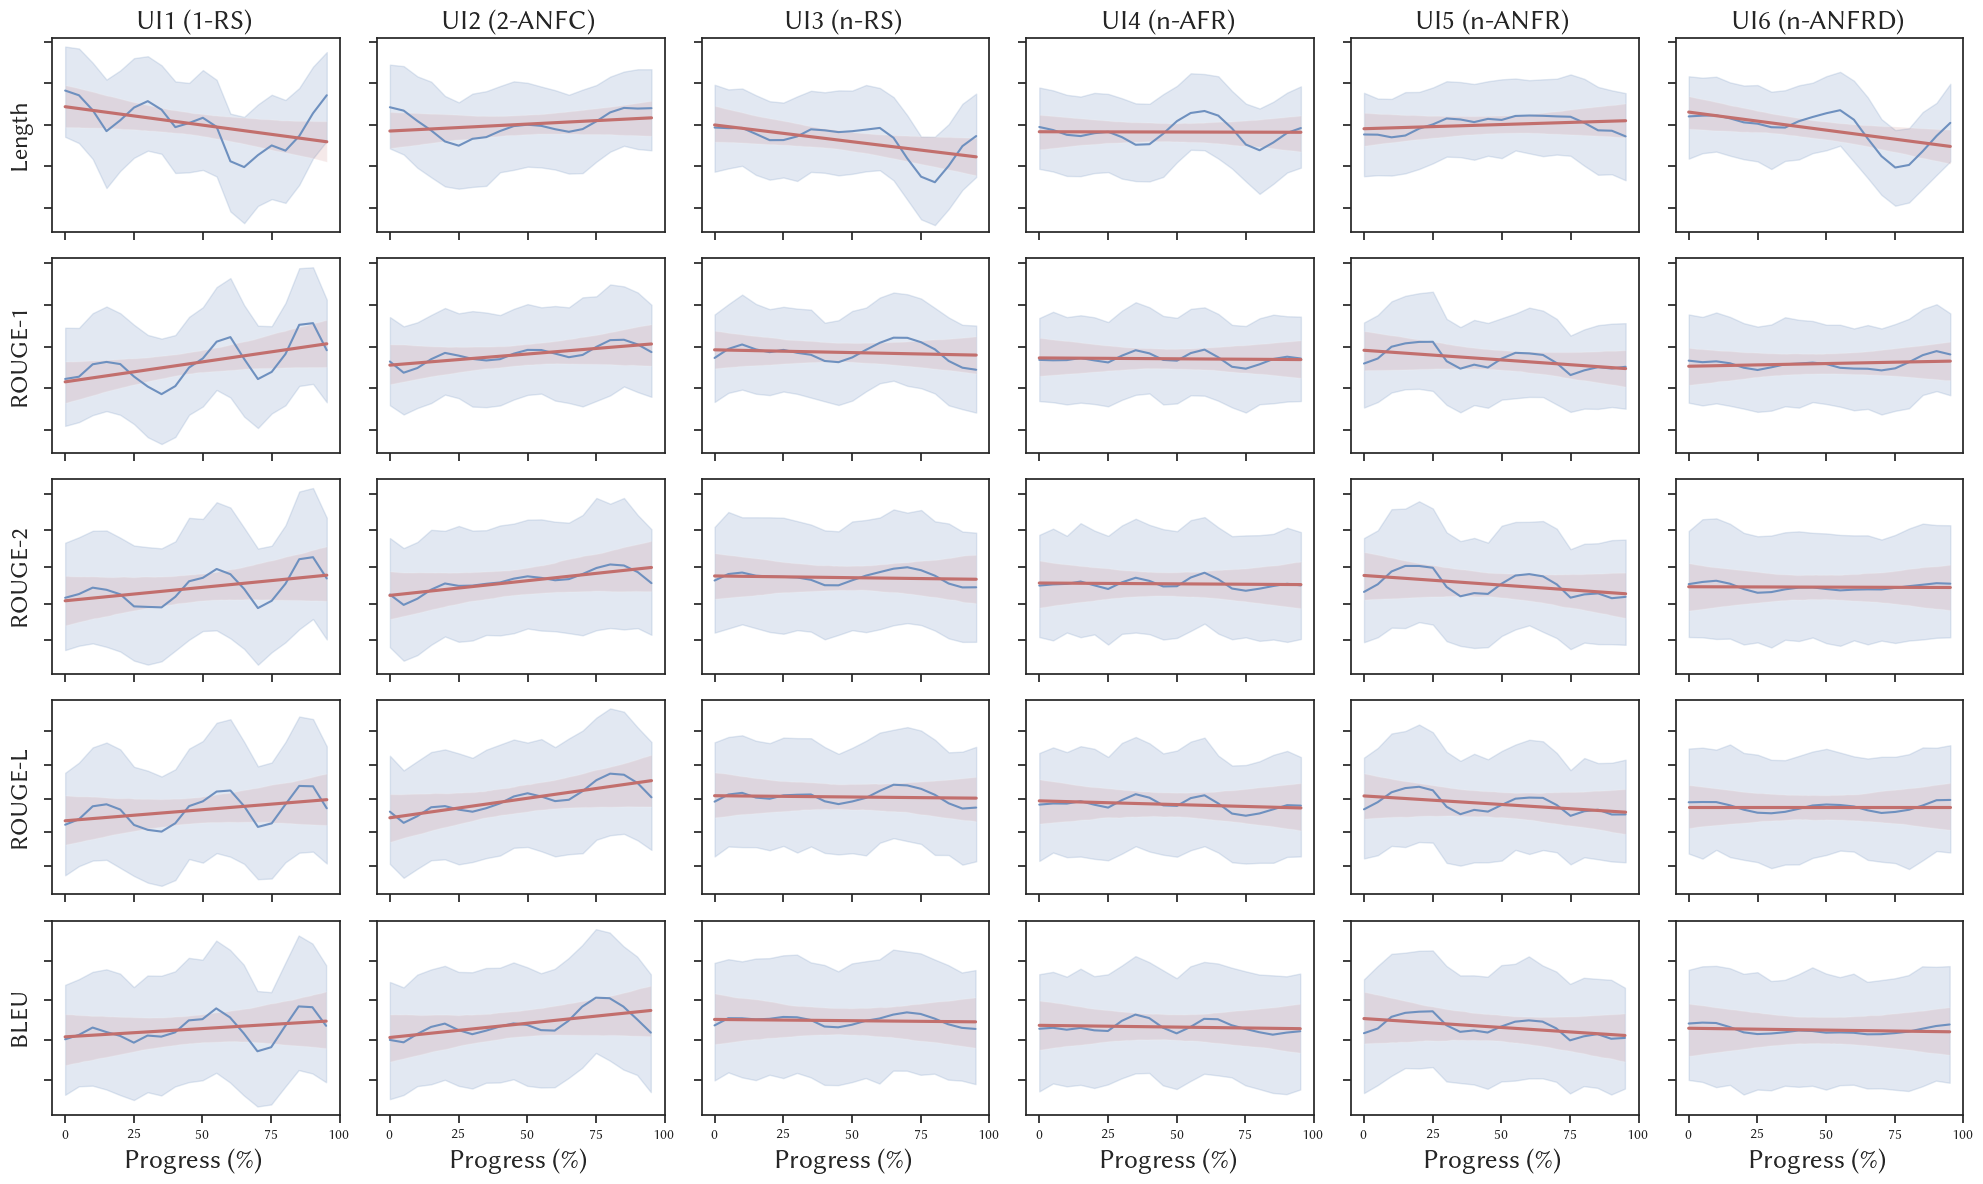

In [6]:
fig, axes = plt.subplots(5, 6, figsize=(20, 12))
colors = ['#6e90bf', '#c26f6d']
interfaces = ['pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking']
metrics = ['length', 'rouge1', 'rouge2', 'rougeL', 'BLEU']
for j in range(5):
    for i in range(6):
        interface = 'pointwise'
        sns.lineplot(ax=axes[j][i], data=df_quality_progress[(df_quality_progress.interface == interfaces[i])], x='iteration', y=metrics[j], color=colors[0])
        sns.regplot(ax=axes[j][i], data=df_quality_progress[(df_quality_progress.interface == interfaces[i])], x='iteration', y=metrics[j], scatter=False, order=1, color=colors[1])

ymin, ymax = axes[0][0].get_ylim()
for j in range(6):
    yi, ya = axes[0][j].get_ylim()
    if ya > ymax:
        ymax = ya
    if yi < ymin:
        ymin = yi


for i in range(5):
    ymin, ymax = axes[i][0].get_ylim()
    for j in range(6):
        yi, ya = axes[i][j].get_ylim()
        if ya > ymax:
            ymax = ya
        if yi < ymin:
            ymin = yi

    for j in range(6):
        axes[i][j].set_ylim(ymin, ymax)
        axes[i][j].set_title('')
        axes[i][j].set_xlabel('')
        axes[i][j].set_ylabel('')
        axes[i][j].set_xticklabels([])
        axes[i][j].set_yticklabels([])
        axes[i][j].legend().remove()

UIs = ['UI1 (1-RS)', 'UI2 (2-ANFC)', 'UI3 (n-RS)', 'UI4 (n-AFR)', 'UI5 (n-ANFR)', 'UI6 (n-ANFRD)']
for i in range(6):
    axes[0][i].set_title(UIs[i], fontsize=20)
metrics = ['Length', 'ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'BLEU']
for i in range(5):
    axes[i][0].set_ylabel(metrics[i], fontsize=18)

for i in range(6):
    axes[4][i].set_xticks([0, 5, 10, 15, 20])
    axes[4][i].set_xticklabels([0, int(500/20), int(1000/20), int(1500/20), 100])
    axes[4][i].set_xlabel('Progress (\%)', fontsize=20)

plt.tight_layout()
plt.savefig('figures/quality_text.pdf', bbox_inches='tight')

In [7]:
df_quality_progress.to_csv('processed/quality_progress_text.csv')

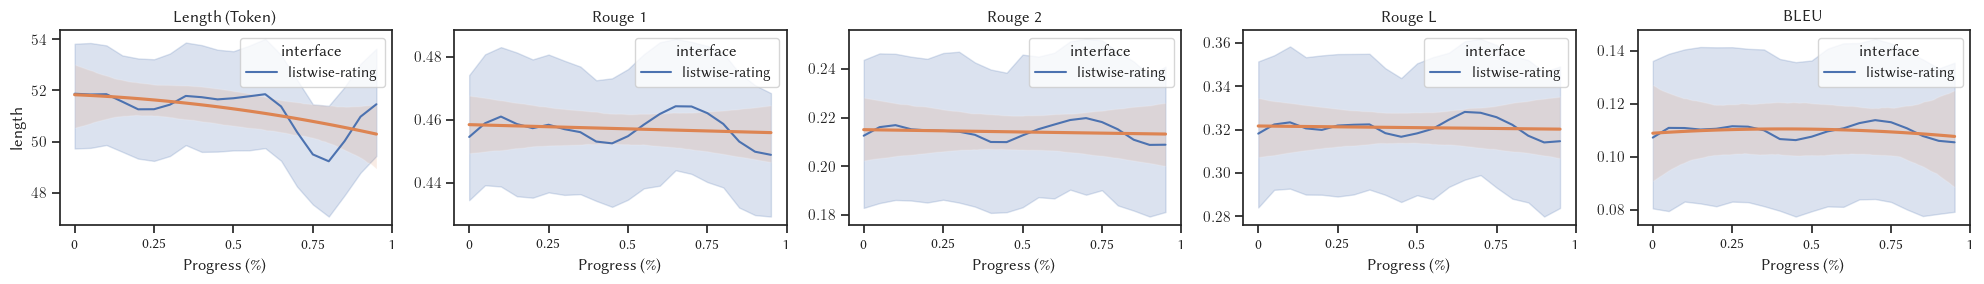

In [8]:
df_quality_progress_draw = df_quality_progress[(df_quality_progress.interface == 'listwise-rating')]

fig, axes = plt.subplots(1, 5, figsize=(20, 3))
sns.lineplot(ax=axes[0], data=df_quality_progress_draw, x='iteration', y='length', hue='interface')
sns.regplot(ax=axes[0], data=df_quality_progress_draw, x='iteration', y='length', scatter=False, order=2)
axes[0].set_xticks([0, 5, 10, 15, 20])
axes[0].set_xticklabels([0, 5/20, 10/20, 15/20, 1])
axes[0].set_xlabel('Progress (\%)')
axes[0].set_title('Length (Token)')

sns.lineplot(ax=axes[1], data=df_quality_progress_draw, x='iteration', y='rouge1', hue='interface')
sns.regplot(ax=axes[1], data=df_quality_progress_draw, x='iteration', y='rouge1', scatter=False)
axes[1].set_xticks([0, 5, 10, 15, 20])
axes[1].set_xticklabels([0, 5/20, 10/20, 15/20, 1])
axes[1].set_xlabel('Progress (\%)')
axes[1].set_title('Rouge 1')
axes[1].set_ylabel('')

sns.lineplot(ax=axes[2], data=df_quality_progress_draw, x='iteration', y='rouge2', hue='interface')
sns.regplot(ax=axes[2], data=df_quality_progress_draw, x='iteration', y='rouge2', scatter=False)
axes[2].set_xticks([0, 5, 10, 15, 20])
axes[2].set_xticklabels([0, 5/20, 10/20, 15/20, 1])
axes[2].set_xlabel('Progress (\%)')
axes[2].set_title('Rouge 2')
axes[2].set_ylabel('')

sns.lineplot(ax=axes[3], data=df_quality_progress_draw, x='iteration', y='rougeL', hue='interface')
sns.regplot(ax=axes[3], data=df_quality_progress_draw, x='iteration', y='rougeL', scatter=False)
axes[3].set_xticks([0, 5, 10, 15, 20])
axes[3].set_xticklabels([0, 5/20, 10/20, 15/20, 1])
axes[3].set_xlabel('Progress (\%)')
axes[3].set_title('Rouge L')
axes[3].set_ylabel('')


sns.lineplot(ax=axes[4], data=df_quality_progress_draw, x='iteration', y='BLEU', hue='interface')
sns.regplot(ax=axes[4], data=df_quality_progress_draw, x='iteration', y='BLEU', scatter=False, order=2)
axes[4].set_xticks([0, 5, 10, 15, 20])
axes[4].set_xticklabels([0, 5/20, 10/20, 15/20, 1])
axes[4].set_xlabel('Progress (\%)')
axes[4].set_title('BLEU')
axes[4].set_ylabel('')

plt.tight_layout()
plt.savefig('figures/quality-listwise-ranking.pdf', bbox_inches='tight')

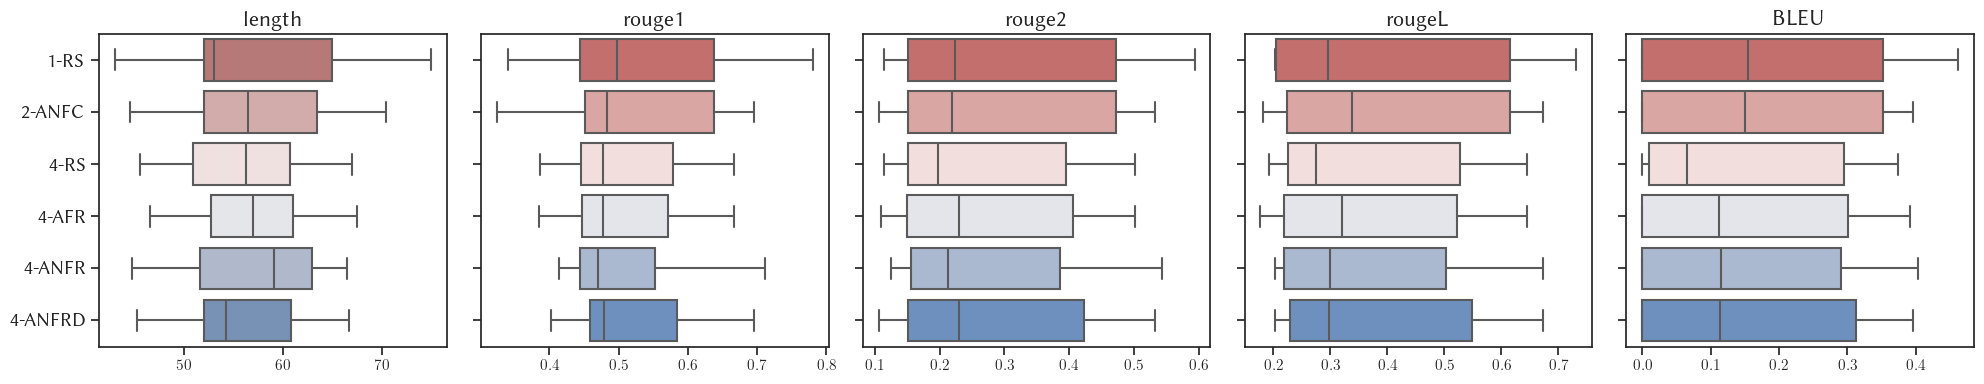

In [9]:
colors = sns.color_palette('vlag', as_cmap=False, n_colors=6)[::-1]
# print(sns.color_palette('vlag', as_cmap=False, n_colors=6).as_hex()[::-1])
colors = ['#c26f6d', '#d9a6a4', '#f2dfdd', '#e4e5eb', '#aab8d0', '#6e90bf']

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
sns.boxplot(ax=axes[0], y='interface', x='length', order=interfaces, data=df_quality[(df_quality.stop==True) & (df_quality.taskID != 1)], palette=colors)
sns.boxplot(ax=axes[1], y='interface', x='rouge1', order=interfaces, data=df_quality[(df_quality.stop==True) & (df_quality.taskID != 1)], palette=colors, saturation=1)
sns.boxplot(ax=axes[2], y='interface', x='rouge2', order=interfaces, data=df_quality[(df_quality.stop==True) & (df_quality.taskID != 1)], palette=colors, saturation=1)
sns.boxplot(ax=axes[3], y='interface', x='rougeL', order=interfaces, data=df_quality[(df_quality.stop==True) & (df_quality.taskID != 1)], palette=colors, saturation=1)
sns.boxplot(ax=axes[4], y='interface', x='BLEU'  , order=interfaces, data=df_quality[(df_quality.stop==True) & (df_quality.taskID != 1)], palette=colors, saturation=1)

labels = ['UI1', 'UI2', 'UI3', 'UI4', 'UI5', 'UI6']
labels = ['1-RS', '2-ANFC', '4-RS', '4-AFR', '4-ANFR', '4-ANFRD']
metrics = ['length', 'rouge1', 'rouge2', 'rougeL', 'BLEU']
for idx, ax in enumerate(axes):
    if idx == 0:
        ax.set_yticklabels(labels, fontsize=14)
    else:
        ax.set_yticklabels([])
    ax.set_xlabel('')
    ax.set_title(metrics[idx], fontsize=16)
    ax.set_ylabel('')
plt.tight_layout()

<AxesSubplot: xlabel='rougeL', ylabel='Count'>

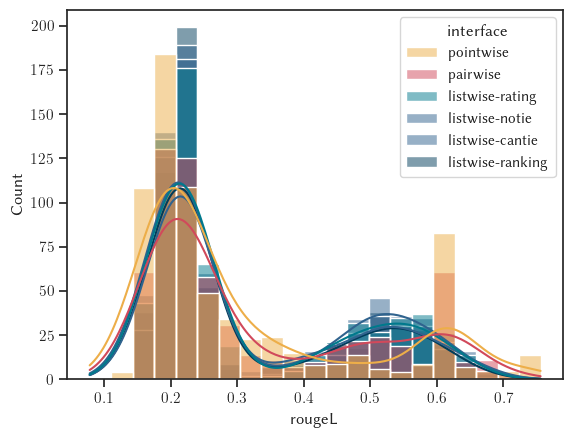

In [10]:
colors = ['#EDAE49', '#D1495B', '#00798C', '#30638E', '#30638E', '#003D5B']
sns.histplot(data=df_quality, x='rougeL', hue='interface', palette=colors, kde=True)

<AxesSubplot: >

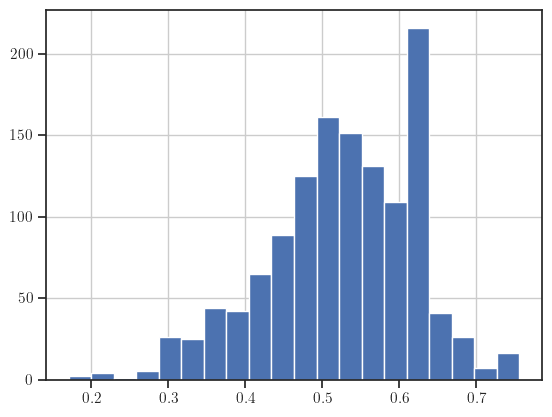

In [11]:
df_quality[df_quality.taskID == 2].rougeL.hist(bins=20)

<AxesSubplot: xlabel='length', ylabel='rouge2'>

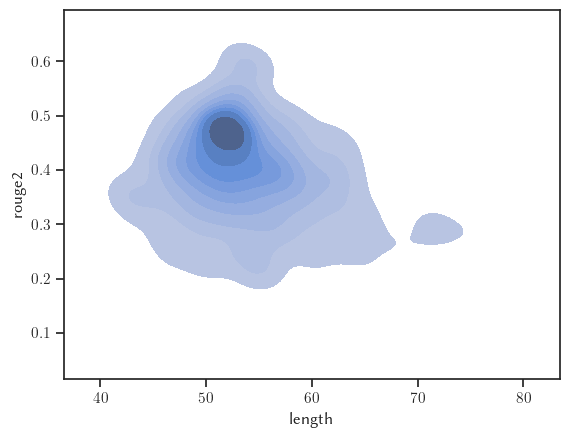

In [12]:
# g = sns.PairGrid(, diag_sharey=False)
# g.map_upper(sns.scatterplot, s=15)
# g.map_lower(sns.kdeplot)
# g.map_diag(sns.kdeplot, lw=2)
x='length'
y='rouge2'
# sns.scatterplot(data=df_quality[df_quality.taskID == 2][['length', 'rouge2', 'BLEU']], x=x, y=y)
# sns.histplot(data=df_quality[df_quality.taskID == 2][['length', 'rouge2', 'BLEU']], x=x, y=y)
sns.kdeplot(data=df_quality[df_quality.taskID == 2][['length', 'rouge2', 'BLEU']], x=x, y=y, fill=True)

<AxesSubplot: xlabel='length', ylabel='BLEU'>

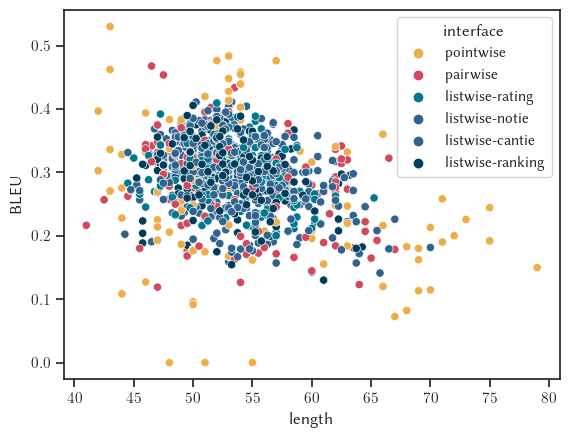

In [13]:
sns.scatterplot(x='length', y='BLEU', data=df_quality[df_quality.taskID == 2], hue='interface', palette=colors)

<AxesSubplot: xlabel='length', ylabel='rougeL'>

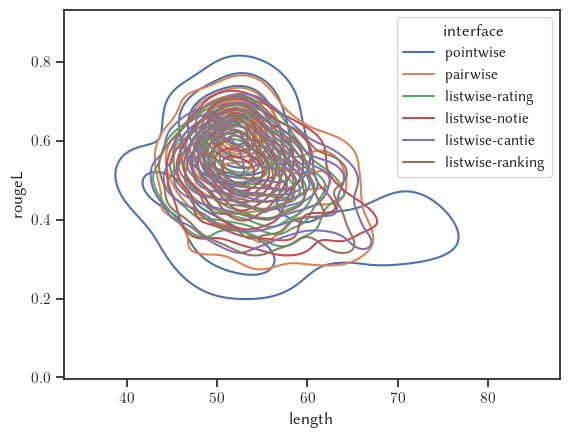

In [14]:
sns.kdeplot(x='length', y='rougeL', data=df_quality[df_quality.taskID == 2], hue='interface')

In [15]:
pairwise_test(df_quality[df_quality.taskID == 2], 'interface', 'BLEU')

TypeError: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''